# Credit Card Fraud: Anomaly Ranking
Statistical baseline vs cluster-based vs classification-based scoring, evaluated as a ranking against withheld labels.

Set `PATH` to your copy of `creditcard.csv`. Figures are saved to `figures2/`.

In [1]:
import pandas as pd, numpy as np, warnings, os, matplotlib.pyplot as plt, time
warnings.filterwarnings('ignore'); os.makedirs('figures2',exist_ok=True)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve, silhouette_score
from sklearn.covariance import EmpiricalCovariance
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.svm import OneClassSVM
pd.set_option('display.width',200)
PATH='/mnt/user-data/uploads/creditcard.csv'
df=pd.read_csv(PATH)
V=[f'V{i}' for i in range(1,29)]
print(df.shape,'missing:',df.isna().sum().sum(),'duplicate rows:',df.duplicated().sum(),'| fraud:',df.Class.sum(),f'({df.Class.mean():.3%})')
print('Time sorted:',df.Time.is_monotonic_increasing,'| Time range (h):',round(df.Time.max()/3600,1))
print(df.groupby('Class').Amount.describe().round(2))
print('zero-amount rows:',(df.Amount==0).sum(),'of which fraud:',((df.Amount==0)&(df.Class==1)).sum())
print('V std range:',df[V].std().min().round(2),'-',df[V].std().max().round(2),'| max |mean|:',df[V].mean().abs().max())
print('max |corr| between V features:',df[V].corr().abs().values[np.triu_indices(28,1)].max())
print(df[V+['Amount','Time']].corrwith(df.Class).abs().sort_values(ascending=False).head(8).round(2))

(284807, 31) missing: 0 duplicate rows: 1081 | fraud: 492 (0.173%)
Time sorted: True | Time range (h): 48.0
          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87
zero-amount rows: 1825 of which fraud: 27
V std range: 0.33 - 1.96 | max |mean|: 4.866698941746315e-15


max |corr| between V features: 2.321486470875369e-14
V17    0.33
V14    0.30
V12    0.26
V10    0.22
V16    0.20
V3     0.19
V7     0.19
V11    0.15
dtype: float64


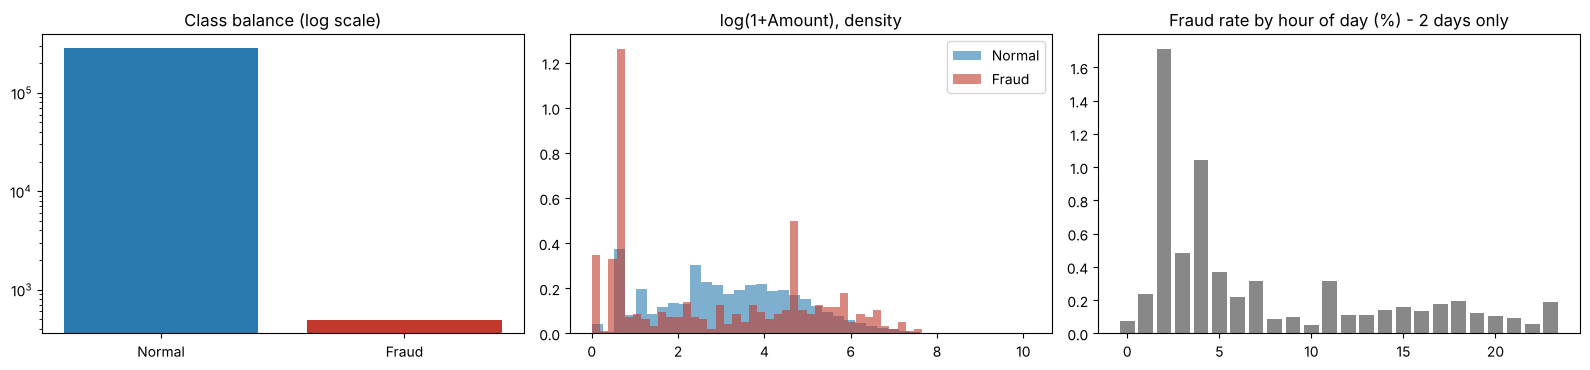

Time         0          1          2          3          4          5          6          7           8          9   ...          14          15          16          17          18          19  \
size  7695.0000  4220.0000  3328.0000  3492.0000  2209.0000  2990.0000  4101.0000  7243.0000  10276.0000  15838.000  ...  16570.0000  16461.0000  16453.0000  16166.0000  17039.0000  15649.0000   
sum      6.0000    10.0000    57.0000    17.0000    23.0000    11.0000     9.0000    23.0000      9.0000     16.000  ...     23.0000     26.0000     22.0000     29.0000     33.0000     19.0000   
mean     0.0008     0.0024     0.0171     0.0049     0.0104     0.0037     0.0022     0.0032      0.0009      0.001  ...      0.0014      0.0016      0.0013      0.0018      0.0019      0.0012   

Time          20          21          22          23  
size  16756.0000  17703.0000  15441.0000  10938.0000  
sum      18.0000     16.0000      9.0000     21.0000  
mean      0.0011      0.0009      0.0006      0.00

In [2]:
hr=(df.Time//3600%24).astype(int); g=df.groupby(hr).Class.agg(['size','sum','mean'])
fig,ax=plt.subplots(1,3,figsize=(16,3.8))
ax[0].bar(['Normal','Fraud'],[ (df.Class==0).sum(),(df.Class==1).sum()],color=['#2a7ab0','#c0392b']);ax[0].set_yscale('log');ax[0].set_title('Class balance (log scale)')
for c,col in [(0,'#2a7ab0'),(1,'#c0392b')]: ax[1].hist(np.log1p(df[df.Class==c].Amount),bins=40,alpha=.6,density=True,color=col,label=['Normal','Fraud'][c])
ax[1].set_title('log(1+Amount), density');ax[1].legend()
ax[2].bar(g.index,g['mean']*100,color='#888');ax[2].set_title('Fraud rate by hour of day (%) - 2 days only');plt.tight_layout();plt.savefig('figures2/01_eda.png',dpi=110);plt.show()
print(g.round(4).T)

## Preparation
* **Features:** V1-V28 (already PCA components: centred, uncorrelated) + log(1+Amount). Amount is extremely right-skewed, so a log transform stops it dominating distances and z-scores.
* **Time dropped:** it is seconds since the first transaction in a 2-day window; it has no meaning outside this extract and would only let a model memorise the calendar. (Hour-of-day shows a fraud-rate pattern, but with only 2 days that is too thin to trust.)
* **Scaling:** standardise with *training-period* statistics only; PCA components have very different variances (std 0.33 to 1.96), so without scaling the first few would dominate Euclidean distance.
* **Split:** chronological, first 70% of time = train, last 30% = test, mimicking deployment (score future transactions). Unsupervised scorers never see labels; the classifier sees only training-period labels.
* **Kept:** duplicates (1,081 rows; legitimate repeat purchases are plausible) and zero-amount rows (27 are fraud - card-testing probes - so they are informative). No missing values, no resampling (ranking metrics cope with imbalance).

In [3]:
cut=int(.7*len(df)); tr,te=df.iloc[:cut].copy(),df.iloc[cut:].copy()
def feats(d): return np.column_stack([d[V].values,np.log1p(d.Amount.values)])
sc=StandardScaler().fit(feats(tr)); Xtr,Xte=sc.transform(feats(tr)),sc.transform(feats(te)); ytr,yte=tr.Class.values,te.Class.values
print('train',Xtr.shape,'frauds',ytr.sum(),'| test',Xte.shape,'frauds',yte.sum(),f'({yte.mean():.3%})')
def evaluate(name,s,y=yte):
    n=len(y); r={'method':name,'ROC-AUC':roc_auc_score(y,s),'PR-AUC (AP)':average_precision_score(y,s)}
    o=np.argsort(-s)
    for p in [0.1,0.5,1.0]:
        k=int(n*p/100); hit=y[o[:k]].sum(); r[f'recall@{p}%']=hit/y.sum(); r[f'prec@{p}%']=hit/k
    return r
R=[]

train (199364, 29) frauds 384 | test (85443, 29) frauds 108 (0.126%)


## Statistical outlier baselines (no labels)

In [4]:
# (a) univariate: robust z of raw Amount
med=tr.Amount.median(); mad=(tr.Amount-med).abs().median()*1.4826
R.append(evaluate('Baseline: Amount robust-z',((te.Amount-med).abs()/mad).values))
# (b) multivariate max |z| over the 29 standardised features
R.append(evaluate('Baseline: max |z| (29 features)',np.abs(Xte).max(1)))
# (c) Mahalanobis distance from training mean/covariance
cov=EmpiricalCovariance().fit(Xtr); maha=cov.mahalanobis(Xte)
R.append(evaluate('Baseline: Mahalanobis distance',maha))
pd.DataFrame(R).round(3)

,method,ROC-AUC,PR-AUC (AP),recall@0.1%,prec@0.1%,recall@0.5%,prec@0.5%,recall@1.0%,prec@1.0%
0,Baseline: Amount robust-z,0.637,0.002,0.0,0.0,0.009,0.002,0.028,0.004
1,Baseline: max |z| (29 features),0.938,0.035,0.0,0.0,0.167,0.042,0.407,0.052
2,Baseline: Mahalanobis distance,0.946,0.034,0.0,0.0,0.093,0.023,0.426,0.054


## Cluster-based: K-means distance to nearest centroid (no labels)
Fraud is assumed to be far from every dense group of normal behaviour. k is chosen from unsupervised criteria only (elbow + silhouette on a 10k sample); the test labels are not used.

In [5]:
rng=np.random.default_rng(0); sidx=rng.choice(len(Xtr),10000,replace=False); rows=[]
for k in [2,4,6,8,10,12,16,24]:
    km=KMeans(k,n_init=3,random_state=0).fit(Xtr); rows.append((k,km.inertia_,silhouette_score(Xtr[sidx],km.labels_[sidx])))
kk=pd.DataFrame(rows,columns=['k','inertia','silhouette']).round(3); display(kk)

,k,inertia,silhouette
0,2,5575335.568,0.057
1,4,5181562.331,0.053
2,6,4850561.172,0.055
3,8,4588566.803,0.066
4,10,4402480.163,0.076
5,12,4240791.504,0.076
6,16,3882774.805,0.075
7,24,3462266.563,0.078


In [6]:
K=10   # chosen a priori from the table above (elbow flattening), not from test labels
km=KMeans(K,n_init=5,random_state=0).fit(Xtr)
dtr=km.transform(Xtr).min(1); dte_all=km.transform(Xte); lab=dte_all.argmin(1); dte=dte_all.min(1)
cmed=np.array([np.median(dtr[km.labels_==c]) for c in range(K)])
R.append(evaluate('Cluster: K-means distance',dte))
R.append(evaluate('Cluster: K-means distance / cluster median',dte/cmed[lab]))
print('cluster sizes (train):',np.bincount(km.labels_).tolist())
# sensitivity to k (information only)
sens=[]
for k in [4,6,10,16,24]:
    m=KMeans(k,n_init=3,random_state=0).fit(Xtr); sens.append((k,average_precision_score(yte,m.transform(Xte).min(1)),roc_auc_score(yte,m.transform(Xte).min(1))))
print(pd.DataFrame(sens,columns=['k','test AP','test AUC']).round(3))

cluster sizes (train): [18570, 16267, 45657, 3138, 232, 23972, 1018, 27379, 51152, 11979]


    k  test AP  test AUC
0   4    0.040     0.948
1   6    0.039     0.948
2  10    0.035     0.938
3  16    0.051     0.929
4  24    0.018     0.922


## Classification-based
* **One-class SVM** trained only on normal training transactions (a boundary around 'normal'; it needs no fraud examples).
* **Gradient-boosted trees** trained on the labelled training period (supervised; fraud is the positive class). Justification: past investigator outcomes exist, fraud is a specific pattern (not just 'far from the centre'), and boosted trees cope with imbalance and non-linear interactions.

In [7]:
t=time.time(); nidx=rng.choice(np.where(ytr==0)[0],8000,replace=False)
oc=OneClassSVM(kernel='rbf',gamma='scale',nu=0.01).fit(Xtr[nidx]); s_oc=-oc.decision_function(Xte)
R.append(evaluate('Classification: One-class SVM (normal only)',s_oc)); print('OCSVM',round(time.time()-t),'s')
t=time.time(); gb=HistGradientBoostingClassifier(max_iter=300,learning_rate=0.08,max_leaf_nodes=15,l2_regularization=1.0,class_weight='balanced',early_stopping=True,validation_fraction=0.15,random_state=0).fit(Xtr,ytr)
s_gb=gb.predict_proba(Xte)[:,1]; R.append(evaluate('Classification: Gradient boosting (supervised)',s_gb)); print('GB',round(time.time()-t),'s, iters',gb.n_iter_)
res=pd.DataFrame(R).set_index('method').round(3); display(res); res.to_csv('results.csv')

OCSVM 2 s


GB 18 s, iters 40


,ROC-AUC,PR-AUC (AP),recall@0.1%,prec@0.1%,recall@0.5%,prec@0.5%,recall@1.0%,prec@1.0%
method,,,,,,,,
Baseline: Amount robust-z,0.637,0.002,0.000,0.000,0.009,0.002,0.028,0.004
Baseline: max |z| (29 features),0.938,0.035,0.000,0.000,0.167,0.042,0.407,0.052
Baseline: Mahalanobis distance,0.946,0.034,0.000,0.000,0.093,0.023,0.426,0.054
Cluster: K-means distance,0.938,0.035,0.000,0.000,0.111,0.028,0.426,0.054
Cluster: K-means distance / cluster median,0.884,0.021,0.000,0.000,0.046,0.012,0.343,0.043
Classification: One-class SVM (normal only),0.941,0.099,0.000,0.000,0.611,0.155,0.750,0.095
Classification: Gradient boosting (supervised),0.977,0.768,0.713,0.906,0.843,0.213,0.870,0.110


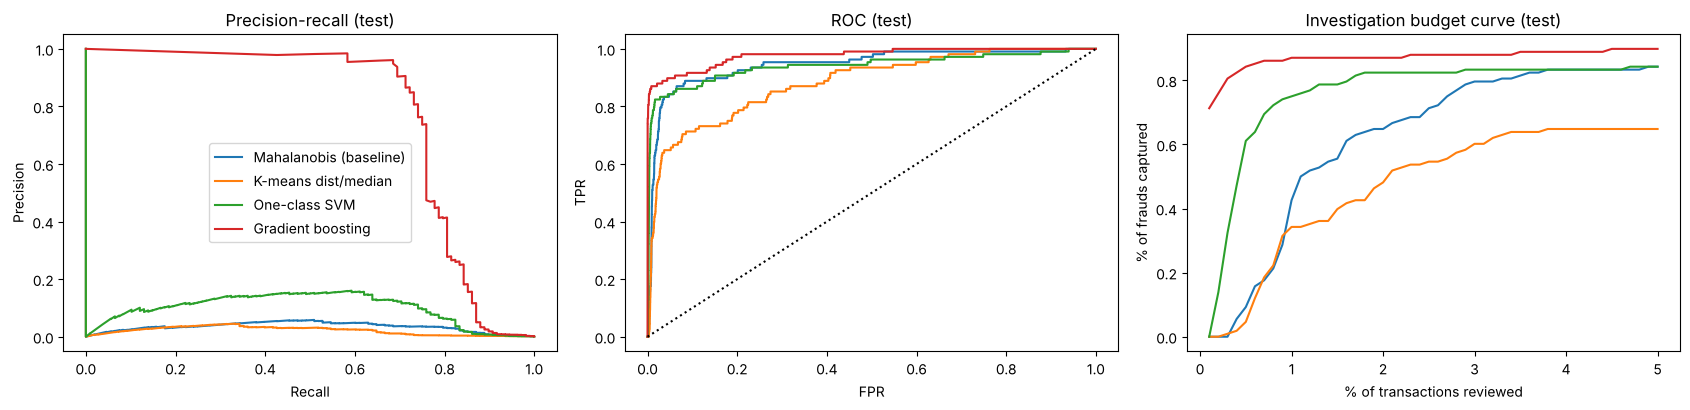

In [8]:
S={'Mahalanobis (baseline)':maha,'K-means dist/median':dte/cmed[lab],'One-class SVM':s_oc,'Gradient boosting':s_gb}
fig,ax=plt.subplots(1,3,figsize=(17,4.2))
for n,s in S.items():
    p,r,_=precision_recall_curve(yte,s); ax[0].plot(r,p,label=n)
    f,t_,_=roc_curve(yte,s); ax[1].plot(f,t_,label=n)
    o=np.argsort(-s); ks=np.linspace(0.001,0.05,50); ax[2].plot(ks*100,[yte[o[:int(len(yte)*k)]].sum()/yte.sum() for k in ks],label=n)
ax[0].set_xlabel('Recall');ax[0].set_ylabel('Precision');ax[0].set_title('Precision-recall (test)');ax[0].legend()
ax[1].plot([0,1],[0,1],'k:');ax[1].set_xlabel('FPR');ax[1].set_ylabel('TPR');ax[1].set_title('ROC (test)')
ax[2].set_xlabel('% of transactions reviewed');ax[2].set_ylabel('% of frauds captured');ax[2].set_title('Investigation budget curve (test)')
plt.tight_layout();plt.savefig('figures2/02_method_comparison.png',dpi=110);plt.show()

## Why an unusual transaction is not necessarily fraud

In [9]:
n=len(yte); out={}
for name,s in S.items():
    o=np.argsort(-s); k=int(n*0.01); flagged=o[:k]; fp=flagged[yte[flagged]==0]
    # operating point at 1% FPR
    thr=np.quantile(s[yte==0],0.99); pred=s>thr; tp=(pred&(yte==1)).sum(); fpn=(pred&(yte==0)).sum()
    out[name]={'top1%: flagged':k,'top1%: frauds':int(yte[flagged].sum()),'top1% precision':round(yte[flagged].mean(),3),
      'FPR=1%: recall':round(tp/yte.sum(),3),'FPR=1%: precision':round(tp/(tp+fpn),3),'FPR=1%: false alarms':int(fpn),
      'frauds scoring below test median':round(float((s[yte==1]<np.median(s)).mean()),3),
      'frauds below 90th pct':round(float((s[yte==1]<np.quantile(s,0.9)).mean()),3)}
display(pd.DataFrame(out).T)
# what do the false alarms of the Mahalanobis baseline look like?
o=np.argsort(-maha)[:int(n*0.01)]; fa=te.iloc[o[yte[o]==0]]
print('Mahalanobis top-1% false alarms: median Amount',fa.Amount.median().round(1),'vs overall test median',te.Amount.median().round(1),
      '| share of Amount above overall p99:',round((fa.Amount>te.Amount.quantile(.99)).mean(),3))
# is a big amount fraud?
top=te.Amount>=te.Amount.quantile(.99); print('fraud rate among top-1% Amount:',round(te[top].Class.mean(),4),'vs base',round(yte.mean(),4))
big=te[te.Class==0].nlargest(5,'Amount'); print('5 largest legit amounts and their anomaly-score percentile (Mahalanobis / GB):')
pm=pd.Series(maha).rank(pct=True).values; pg=pd.Series(s_gb).rank(pct=True).values
print(pd.DataFrame({'Amount':big.Amount.values,'maha pct':pm[te.index.get_indexer(big.index)].round(3),'gb pct':pg[te.index.get_indexer(big.index)].round(3)}))
# base-rate arithmetic
for rec,fpr in [(0.8,0.01),(0.8,0.001)]:
    tp=rec*yte.sum(); fp=fpr*(yte==0).sum(); print(f'recall {rec:.0%}, FPR {fpr:.1%} -> precision {tp/(tp+fp):.1%}, {fp:.0f} false alarms per {tp:.0f} frauds caught')
# which features drive GB (permutation on a test subsample)
from sklearn.inspection import permutation_importance
sub=np.concatenate([np.where(yte==1)[0],rng.choice(np.where(yte==0)[0],8000,replace=False)])
pi=permutation_importance(gb,Xte[sub],yte[sub],scoring='average_precision',n_repeats=3,random_state=0)
names=V+['log_Amount']; print(pd.Series(pi.importances_mean,index=names).sort_values(ascending=False).head(6).round(3))

,top1%: flagged,top1%: frauds,top1% precision,FPR=1%: recall,FPR=1%: precision,FPR=1%: false alarms,frauds scoring below test median,frauds below 90th pct
Mahalanobis (baseline),854.0,46.0,0.054,0.472,0.056,854.0,0.028,0.111
K-means dist/median,854.0,37.0,0.043,0.343,0.042,854.0,0.065,0.287
One-class SVM,854.0,81.0,0.095,0.759,0.088,854.0,0.037,0.139
Gradient boosting,854.0,94.0,0.110,0.870,0.099,854.0,0.009,0.083


Mahalanobis top-1% false alarms: median Amount 43.1 vs overall test median 20.0 | share of Amount above overall p99: 0.205
fraud rate among top-1% Amount: 0.0034 vs base 0.0013
5 largest legit amounts and their anomaly-score percentile (Mahalanobis / GB):
     Amount  maha pct  gb pct
0  25691.16     1.000   1.000
1  10199.44     1.000   0.997
2  10000.00     1.000   0.992
3   8787.00     0.999   0.988
4   8360.00     1.000   0.990
recall 80%, FPR 1.0% -> precision 9.2%, 853 false alarms per 86 frauds caught
recall 80%, FPR 0.1% -> precision 50.3%, 85 false alarms per 86 frauds caught


V14    0.084
V4     0.059
V12    0.042
V10    0.022
V17    0.015
V7     0.003
dtype: float64
